# A minimum demo

This is a minimum demo to get started with FastCCC: one call runs the analysis, and the second half checks FastCCC's analytic p-values against CellPhoneDB's permutation test on the same data.

For detailed usage instructions, the command line, comparison against the healthy tissue reference panels and steps to build your own reference panel, please visit the [documentation](https://svvord.github.io/FastCCC/).

## Data

- `normalised_log_counts.h5ad` and `metadata.tsv`: the example dataset of the CellPhoneDB tutorials (3,312 cells, 42 cell types).
- Three sets of CellPhoneDB results on that dataset, each from 1,000 permutations, used as ground truth below: `1k_t20` (CellPhoneDB's score, the mean), `1k_t20_qt` (the 90th percentile instead of the mean) and `1k_t20_qt_multiply` (the 90th percentile, ligand and receptor combined by the geometric mean).

Set `DATA` to the folder that holds them.

In [1]:
import glob
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from loguru import logger

import fastccc

logger.remove()          # keeps this notebook short; drop the line to see FastCCC's progress messages

DATA = 'example'
OUT = 'fastccc_demo_results'
counts_file_path = f'{DATA}/normalised_log_counts.h5ad'
meta_file_path = f'{DATA}/metadata.tsv'
print('FastCCC', fastccc.__version__)

FastCCC 1.1.0


## Run FastCCC

`fastccc.run` reads the expression matrix and the cell-type labels, scores every ligand–receptor pair between every pair of cell types and combines the scoring modules with the Cauchy test. The database ships with the package. By default sixteen modules are scored; here four are selected (two expression summaries, the mean and the 90th percentile, times two ligand–receptor combinations), the ones the CellPhoneDB results below were computed for.

The same from the command line: `fastccc run normalised_log_counts.h5ad --celltype-file metadata.tsv --db CPDBv4.1.0 --summary Mean --summary Quantile_0.9 --aggregation Minimum --combination Arithmetic --combination Geometric`.

In [2]:
res = fastccc.run(
    counts_file_path,
    celltype_file=meta_file_path,
    database='CPDBv4.1.0',
    out_dir=OUT,
    single_unit_summary_list=['Mean', 'Quantile_0.9'],
    complex_aggregation_list=['Minimum'],
    LR_combination_list=['Arithmetic', 'Geometric'],
)
print(f'{len(res.celltypes)} cell types, {len(res.significant):,} significant interactions (Cauchy p < 0.05)')
print('interactive result page:', os.path.join(OUT, 'explorer.html'))
res.significant.head()

42 cell types, 68,422 significant interactions (Cauchy p < 0.05)
interactive result page: fastccc_demo_results/explorer.html


,sender_celltype,receiver_celltype,LRI_ID,ligand,receptor,p-value
0,B_cells,B_cells,CPI-SS080C81D37,APP,CD74,8.809538e-04
1,B_cells,B_cells,CPI-SC0713C9654,COL22A1,"ITGB1,ITGA1",4.237689e-02
2,B_cells,B_cells,CPI-SS0669CC233,CXCL14,CXCR4,2.962364e-03
3,B_cells,B_cells,CPI-SS000568A0E,FCER2,CR2,7.863171e-11
4,B_cells,B_cells,CPI-SC0F96CE387,FN1,"ITGB1,ITGA4",2.040776e-02


Open `explorer.html` in a browser to explore the result: filters, sender × receiver heatmap, dot plot, signalling roles, pathway families, per-interaction evidence, and SVG / CSV export.

## Results comparison

The following results are obtained using CellPhoneDB or a modified version of CellPhoneDB (e.g., using quantile instead of mean for summary computation) as the permutation test ground truth to validate the accuracy of our method’s p-value estimation.

Important Notes:
- We discovered that CellPhoneDB v4 and v5.0.0, when utilizing multithreading, may produce identical results across multiple threads due to improper handling of random seeds. This means that instead of 1000 independent permutations, only about 100 unique and effective permutations may be generated. (As of the time of our study, 2024-Dec, this bug was still present; we are uncertain whether it has been fixed in the latest CellPhoneDB release.)
- To ensure fair comparisons, we modified CellPhoneDB’s random seed settings to eliminate this issue.
- If you are simply looking to validate our analytical p-value estimation using CellPhoneDB, we recommend setting thread=1 to avoid multithreading-induced biases. This will ensure correct results, albeit at the cost of increased runtime.

We emphasize that all results reported in our study are fair and unbiased. We have not downgraded any competing method’s performance. Instead, we have actively optimized other methods where possible (e.g., fixing bugs) to ensure that their results and efficiency are maximized before comparison with our approach.

The results show that FastCCC’s calculations for each branch closely match those obtained through permutation testing, indicating the correctness of our algorithm’s implementation.

In [3]:
def fastccc_table(module, kind):
    """A per-module table written by the run: rows are sender|receiver, columns are interaction ids."""
    return pd.read_csv(glob.glob(f'{OUT}/*_{module}_{kind}.tsv')[0], sep='\t', index_col=0)


def cellphonedb_table(folder, stamp, kind, like):
    """A CellPhoneDB table in the same layout (its first ten columns annotate the interaction)."""
    t = pd.read_csv(f'{DATA}/{folder}/statistical_analysis_{kind}_{stamp}.txt', sep='\t', index_col=0).iloc[:, 10:].T
    return t.reindex(index=like.index, columns=like.columns)


summary = []


def compare(module, folder, stamp, title):
    score, pval = fastccc_table(module, 'interactions_strength'), fastccc_table(module, 'pvals')
    tested = fastccc_table(module, 'percents_analysis').to_numpy(dtype=bool)      # pairs that pass the expression filter
    score_cpdb = cellphonedb_table(folder, stamp, 'means', score)
    pval_cpdb = cellphonedb_table(folder, stamp, 'pvalues', pval)
    max_error = np.abs(score.to_numpy() - score_cpdb.to_numpy()).max()
    est, pgt = pval.to_numpy()[tested], pval_cpdb.to_numpy()[tested]
    r = np.corrcoef(pgt, est)[0, 1]
    same_call = ((est < 0.05) == (pgt < 0.05)).mean()
    summary.append({'score': title, 'interactions tested': int(tested.sum()), 'max score difference': max_error,
                    'Pearson r of p-values': r, 'same call at p < 0.05': same_call})
    print(f'{title}: max score difference {max_error:.1e}, Pearson r of p-values {r:.4f}, same call at p < 0.05 for {same_call:.1%}')

    floor = 1e-3      # 1,000 permutations resolve p-values down to 0.001; both axes are clipped there on the log panels
    lg, le = -np.log10(np.clip(pgt, floor, 1)), -np.log10(np.clip(est, floor, 1))
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), constrained_layout=True)
    axes[0].scatter(pgt, est, s=1, alpha=0.1, rasterized=True)
    axes[0].plot((0, 1), (0, 1), c='r')
    axes[0].set(title='$p$-value', ylabel='FastCCC')
    axes[1].scatter(lg, le, s=1, alpha=0.1, rasterized=True)
    axes[1].plot((0, 3), (0, 3), c='r', alpha=0.5)
    axes[1].set(title='$-\\log_{10}(p$-value$)$', xlabel='CellPhoneDB (1,000 permutations)')
    sig = pgt < 0.05
    axes[2].scatter(lg[sig], le[sig], s=1, alpha=0.1, rasterized=True)
    axes[2].plot((1.3, 3), (1.3, 3), c='r', alpha=0.5)
    axes[2].set(title='$-\\log_{10}(p$-value$),\\ p < 0.05$')
    fig.suptitle(title)
    plt.show()

### CellPhoneDB's score: mean expression

Mean, arithmetic: max score difference 1.2e-06, Pearson r of p-values 0.9972, same call at p < 0.05 for 98.4%


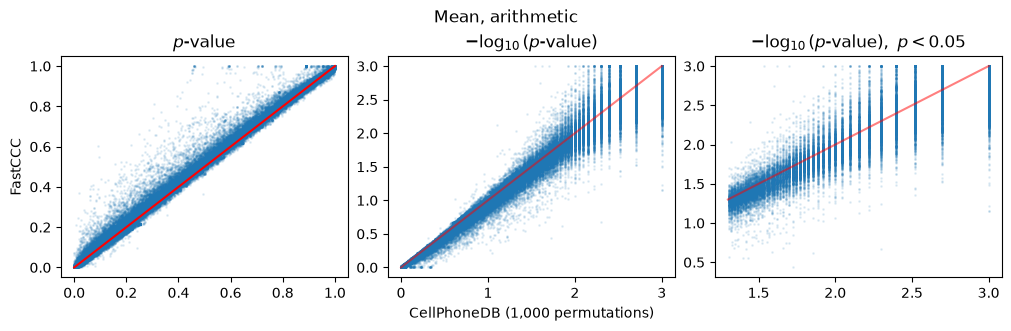

In [4]:
compare('Mean_Minimum_Arithmetic', '1k_t20', '05_02_2024_144734', 'Mean, arithmetic')

### 90th percentile instead of the mean

90th percentile, arithmetic: max score difference 4.0e-07, Pearson r of p-values 0.9998, same call at p < 0.05 for 99.2%


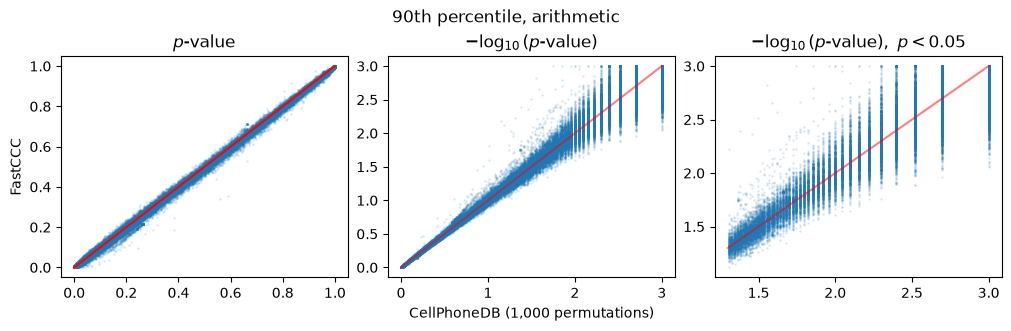

In [5]:
compare('Quantile_0.9_Minimum_Arithmetic', '1k_t20_qt', '06_07_2024_105636', '90th percentile, arithmetic')

### 90th percentile, ligand and receptor combined by the geometric mean

90th percentile, geometric: max score difference 4.0e-07, Pearson r of p-values 0.9998, same call at p < 0.05 for 99.2%


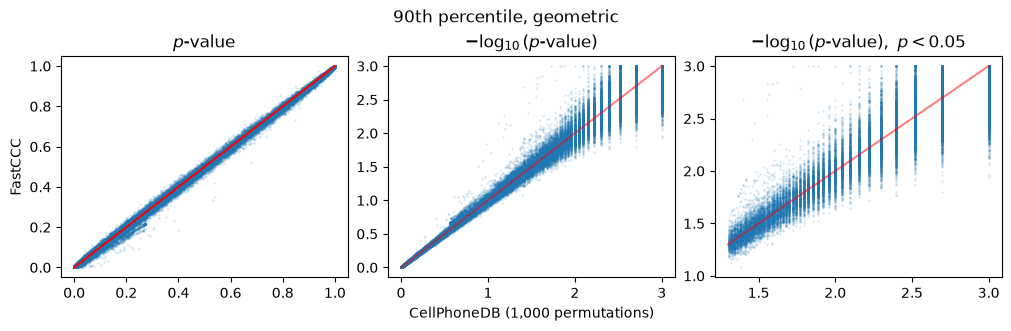

In [6]:
compare('Quantile_0.9_Minimum_Geometric', '1k_t20_qt_multiply', '06_10_2024_205606', '90th percentile, geometric')

### Summary

In [7]:
pd.DataFrame(summary).set_index('score').style.format({'interactions tested': '{:,}', 'max score difference': '{:.1e}',
                                                     'Pearson r of p-values': '{:.4f}', 'same call at p < 0.05': '{:.1%}'})

,interactions tested,max score difference,Pearson r of p-values,same call at p < 0.05
score,,,,
"Mean, arithmetic","125,299",1.2e-06,0.9972,98.4%
"90th percentile, arithmetic","125,299",4.0e-07,0.9998,99.2%
"90th percentile, geometric","125,299",4.0e-07,0.9998,99.2%


## Where to go next

- Compare a dataset with healthy tissue: `fastccc ref data.h5ad -c cell_type -r liver --auto-map`, see [Reference comparison](https://svvord.github.io/FastCCC/guides/reference.html).
- All sixteen scoring modules, conditions and samples, bootstrap support: the [guides](https://svvord.github.io/FastCCC/guides).
- The original functions (`fastccc.statistical_analysis_method`, `fastccc.Cauchy_combination_of_statistical_analysis_methods`) remain available and write the same tables.